# Задание 3.3
## Цепная линия

### Условие:
Исследовать форму равновесия однородной тяжёлой нерастяжимой нити (цепи), подвешенной за два конца под действием силы тяжести: (1) вывод дифференциального уравнения и его решение; (2) статическая картинка (png); (3) анимация.

---
## 1. Аналитическое решение

### 1.1. Модель
Цепь однородная: **линейная плотность** $\rho$ (масса на единицу длины) постоянна; она гибкая (натяжение направлено вдоль касательной) и нерастяжимая. Ось $y$ вертикальна вверх, ось $x$ горизонтальна, форма цепи $y=y(x)$. Цепь находится в равновесии, поэтому сумма сил на любой её участок равна нулю.

### 1.2. Условия равновесия элемента цепи
Рассмотрим участок цепи от **самой нижней точки** (вершины, $x=0$, там касательная горизонтальна) до произвольной точки $(x,y)$. Длина этого участка по дуге — $s$. На него действуют три силы:
1. натяжение $\vec T_0$ в нижней точке: горизонтально, величина $H$ (направлено влево);
2. натяжение $\vec T$ в точке $(x,y)$, направлено вдоль касательной под углом $\varphi$ к горизонту (вправо-вверх);
3. вес участка $\rho g s$ (вниз).

Равновесие по осям:
$$
\text{горизонталь:}\quad T\cos\varphi=H,\qquad\qquad \text{вертикаль:}\quad T\sin\varphi=\rho g\,s .
$$
Из первого уравнения: **горизонтальная составляющая натяжения одинакова во всех точках** цепи ($=H$). Разделив второе на первое:
$$
\tan\varphi=\frac{\rho g}{H}\,s=\frac sa,\qquad a:=\frac{H}{\rho g}.
$$
Но $\tan\varphi=y'(x)$ (угловой коэффициент касательной), поэтому
$$
y'(x)=\frac{s}{a}.
$$

### 1.3. Дифференциальное уравнение
Продифференцируем по $x$ и используем $\dfrac{ds}{dx}=\sqrt{1+y'^2}$ (элемент длины дуги $ds=\sqrt{dx^2+dy^2}$):
$$
\boxed{\ y''=\frac1a\sqrt{1+y'^2}\ }\qquad a=\frac{H}{\rho g}.
$$

### 1.4. Решение методом разделения переменных
Обозначим $p=y'$. Тогда $\dfrac{dp}{dx}=\dfrac1a\sqrt{1+p^2}$, т. е. $\dfrac{dp}{\sqrt{1+p^2}}=\dfrac{dx}{a}$. Интегрируем (табличный интеграл $\int\frac{dp}{\sqrt{1+p^2}}=\operatorname{arsh}p$):
$$
\operatorname{arsh}p=\frac xa+C_1 .
$$
В вершине $x=0$ касательная горизонтальна, $p(0)=0$, значит, $C_1=0$ и
$$
y'=\sinh\frac xa .
$$
Интегрируем ещё раз: $y=a\cosh\dfrac xa+C_2$. Постоянная $C_2$ определяется выбором начала отсчёта по оси $y$: поместим начало координат так, чтобы вершина была на высоте $a$ (то есть **директриса** цепной линии — прямая $y=0$):
$$
\boxed{\ y=a\cosh\frac xa\ }
$$
Это и есть **цепная линия** ($\cosh$ — гиперболический косинус).

### 1.5. Физический смысл параметра $a$ и свойства кривой
- $a=\dfrac{H}{\rho g}$ — отношение горизонтального натяжения к весу единицы длины; это **масштаб длины** («длина цепи, вес которой равен горизонтальному натяжению»). Чем **больше натяжение** $H$ (или **легче** цепь), тем **больше** $a$ и тем **более плоской** выглядит цепная линия: вблизи вершины $y\approx a+\dfrac{x^2}{2a}$ — парабола с малой кривизной $1/a$. Чем **тяжелее** цепь (больше $\rho$), тем $a$ меньше и провисание сильнее. Форма зависит **только от $a$**; сама цепная линия подобна при изменении $a$ (если масштабировать $x,y$ в $a$ раз).
- Длина дуги от вершины: $s=\displaystyle\int_0^x\sqrt{1+y'^2}\,dx=a\sinh\frac xa$ (и действительно $y'=s/a$).
- Натяжение: $T=\sqrt{H^2+(\rho gs)^2}=H\cosh\dfrac xa=\rho g\,y$. **Натяжение в точке равно весу столба цепи высотой $y$ над директрисой.**
- Радиус кривизны: $R=\dfrac{(1+y'^2)^{3/2}}{y''}=\dfrac{a^2\cosh^3(x/a)}{a\cosh(x/a)}\cdot\dfrac1a\cdot a=\dfrac{y^2}{a}$; в вершине $R=a$.
- Цепь, подвешенная в точках $x=\pm L$ на одной высоте, имеет длину $\ell=2a\sinh\dfrac La$ и провисание $h=a\bigl(\cosh\dfrac La-1\bigr)$. По заданным $L$ и $\ell$ параметр $a$ находится численно из уравнения $a\sinh(L/a)=\ell/2$.
- Для цепи на опорах: равновесие по вертикали $2T_{\rm конц}\sin\varphi_{\rm конц}=\rho g\ell$ (опоры держат вес цепи).

## 2. Код: формулы и проверка

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from scipy.optimize import brentq, minimize
from scipy.integrate import solve_ivp
from IPython.display import HTML, Image, display

g = 9.81                                           # м/с²

def catenary(x, a, y_vertex=None):
    # y = a·ch(x/a). Если задана высота вершины y_vertex, кривая сдвигается по вертикали.
    y = a*np.cosh(x/a)
    return y if y_vertex is None else y - a + y_vertex

def solve_a(L, ell):
    # Параметр a по полупролёту L и длине цепи ell из уравнения a·sh(L/a) = ell/2 (ell > 2L).
    f = lambda a: a*np.sinh(L/a) - ell/2
    return brentq(f, 0.05, 1e4)                    # метод Брента на отрезке [0.05, 10000] (sinh не переполняется)

def sag(a, L):
    # Провисание h = a(ch(L/a) − 1) — разность высот опоры и вершины
    return a*(np.cosh(L/a) - 1)

### Проверка 1 (символьная, `sympy`): $y=a\cosh(x/a)$ удовлетворяет $y''=\frac1a\sqrt{1+y'^2}$, а $T=\rho g y$

In [2]:
import sympy as sp

x, a_s, rg = sp.symbols('x a rho_g', positive=True)       # rho_g = ρg
y = a_s*sp.cosh(x/a_s)
print('y\'\' − (1/a)·√(1+y\'²) =', sp.simplify(sp.diff(y, x, 2) - sp.sqrt(1 + sp.diff(y, x)**2)/a_s))   # ожидаем 0
s_arc = a_s*sp.sinh(x/a_s)                                  # длина дуги от вершины
print('y\' − s/a               =', sp.simplify(sp.diff(y, x) - s_arc/a_s))                           # ожидаем 0
H = rg*a_s                                                  # горизонтальное натяжение H = ρg·a
T = sp.sqrt(H**2 + (rg*s_arc)**2)                           # T² = H² + (ρg s)²
print('T − ρg·y                =', sp.simplify(sp.simplify(T) - rg*y))                              # ожидаем 0
R_curv = sp.simplify((1 + sp.diff(y, x)**2)**sp.Rational(3, 2)/sp.diff(y, x, 2))
print('радиус кривизны R − y²/a =', sp.simplify(R_curv - y**2/a_s))                                  # ожидаем 0

y'' − (1/a)·√(1+y'²) = 0
y' − s/a               = 0
T − ρg·y                = 0
радиус кривизны R − y²/a = 0


### Проверка 2 (численная): решаем дифференциальное уравнение `solve_ivp`
Интегрируем $y''=\frac1a\sqrt{1+y'^2}$ с условиями $y(0)=a$, $y'(0)=0$ и сравниваем с $a\cosh(x/a)$.

In [3]:
a0 = 1.5
rhs = lambda x, u: [u[1], np.sqrt(1 + u[1]**2)/a0]          # u = (y, y');  y'' = √(1+y'²)/a
sol = solve_ivp(rhs, (0, 3), [a0, 0.0], rtol=1e-11, atol=1e-12, dense_output=True)
xs = np.linspace(0, 3, 50)
print('max |y_числ − a·ch(x/a)| =', np.max(np.abs(sol.sol(xs)[0] - catenary(xs, a0))))

max |y_числ − a·ch(x/a)| = 1.8755663688807545e-11


### Проверка 3 (независимая, минимум потенциальной энергии)
Цепь в равновесии **минимизирует потенциальную энергию**. Разобьём цепь длины $\ell=6$ м на 30 звеньев, закрепим концы в $(\pm2,\,0)$ и найдём положение узлов, минимизируя $\sum\rho g\,y_{\rm середины}\,\Delta s$ при условии, что длина каждого звена постоянна (метод `SLSQP`). Сравниваем с цепной линией, параметр $a$ которой найден из $a\sinh(L/a)=\ell/2$.

In [4]:
L, ell, N = 2.0, 6.0, 30                                    # полупролёт, длина цепи, число звеньев
a_c = solve_a(L, ell); ds = ell/N
x_nodes = np.linspace(-L, L, N + 1)                         # начальное приближение: равномерно по x, парабола
y_init = -0.8*(1 - (x_nodes/L)**2)

def unpack(v):                                              # v -> полные массивы узлов (концы закреплены)
    X = np.concatenate([[-L], v[:N - 1], [L]]); Y = np.concatenate([[0.0], v[N - 1:], [0.0]])
    return X, Y

def energy(v):                                              # потенциальная энергия (ρg = 1): Σ y_середины·ds
    X, Y = unpack(v); return np.sum(0.5*(Y[1:] + Y[:-1]))*ds

def links(v):                                               # условия: длина каждого звена = ds (нужно 0)
    X, Y = unpack(v); return np.diff(X)**2 + np.diff(Y)**2 - ds**2

v0 = np.concatenate([x_nodes[1:-1], y_init[1:-1]])
res = minimize(energy, v0, constraints={'type': 'eq', 'fun': links}, method='SLSQP', options={'maxiter': 500, 'ftol': 1e-12})
Xn, Yn = unpack(res.x)
Yn_cat = catenary(Xn, a_c) - a_c*np.cosh(L/a_c)             # цепная линия, опущенная так, чтобы концы были на y = 0
print(f'a (из ℓ и L) = {a_c:.5f} м;  оптимизация сошлась: {res.success}')
print(f'провисание: цепная линия h = {sag(a_c, L):.5f} м;  минимизация энергии: {-Yn.min():.5f} м')
print('max |y_узла − y_цепной линии| =', np.max(np.abs(Yn - Yn_cat)), '  (малая разность ~ шаг дискретизации)')

a (из ℓ и L) = 1.23295 м;  оптимизация сошлась: True
провисание: цепная линия h = 2.01053 м;  минимизация энергии: 2.01197 м
max |y_узла − y_цепной линии| = 0.0014415771481610662   (малая разность ~ шаг дискретизации)


### Проверка 4: баланс сил на опорах
Натяжение на конце $T_{\rm конц}=\rho g\,a\cosh(L/a)$, угол $\tan\varphi=\sinh(L/a)$. Вертикальные составляющие обоих концов должны уравновешивать вес всей цепи.

In [5]:
rho = 1.0                                                   # кг/м
T_end = rho*g*a_c*np.cosh(L/a_c); phi = np.arctan(np.sinh(L/a_c))
print(f'T_конц = {T_end:.4f} Н,   угол с горизонтом φ = {np.degrees(phi):.3f}°')
print(f'2·T·sinφ = {2*T_end*np.sin(phi):.5f} Н;   вес цепи ρ·g·ℓ = {rho*g*ell:.5f} Н')
print(f'горизонтальное натяжение H = T cosφ = {T_end*np.cos(phi):.5f} Н;  ρ g a = {rho*g*a_c:.5f} Н')

T_конц = 31.8185 Н,   угол с горизонтом φ = 67.658°
2·T·sinφ = 58.86000 Н;   вес цепи ρ·g·ℓ = 58.86000 Н
горизонтальное натяжение H = T cosφ = 12.09520 Н;  ρ g a = 12.09520 Н


## 3. Статическая визуализация (сохраняется в `task_3_3_static.png`)
**(1)** семейство цепных линий $y=a\cosh(x/a)$ при разных $a$ (директриса $y=0$, вершины $(0,a)$; штриховая линия — парабола $a+x^2/2a$ для $a=1$); **(2)** физические свойства для $a=1{,}5$: участок цепи от вершины до точки $P$ длиной $s$ и треугольник сил $H$, $\rho g s$, $T$; $T=\rho g y$; **(3)** цепь на опорах $x=\pm2$ (одна высота) для разных длин $\ell$ (точки — численная минимизация энергии); **(4)** параметр $a$, провисание $h$ и натяжение на опоре в зависимости от длины цепи.

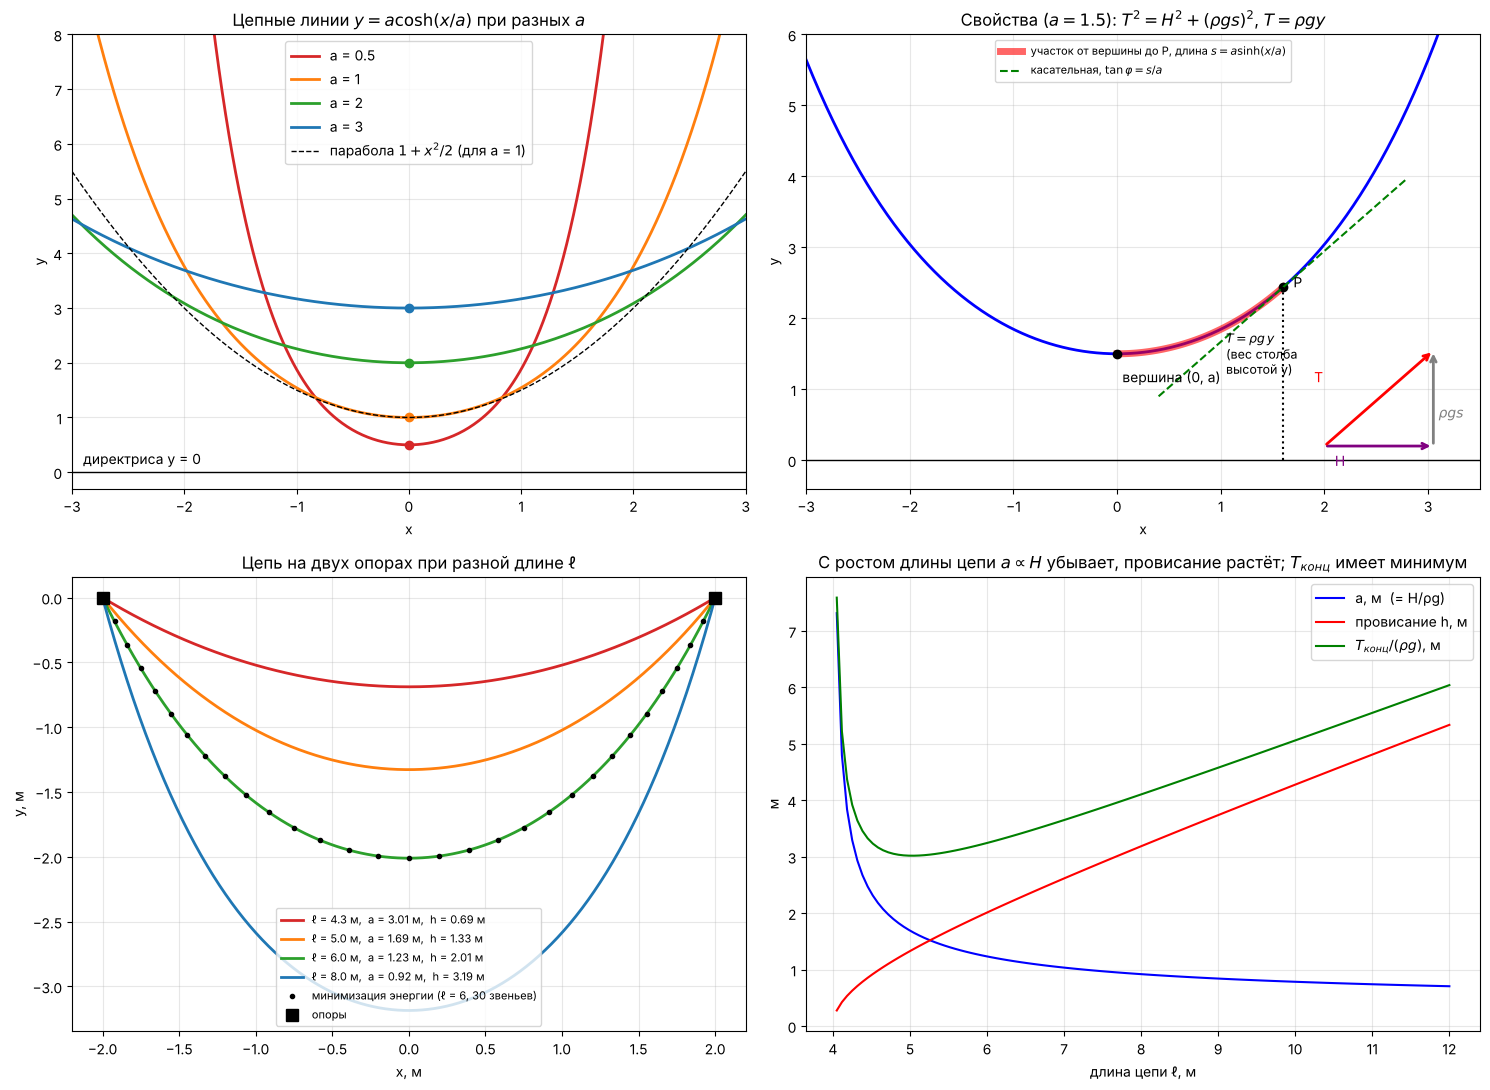

In [6]:
fig, axs = plt.subplots(2, 2, figsize=(15, 11))

# ---- (1) семейство цепных линий ----
ax = axs[0, 0]; xx = np.linspace(-3, 3, 400)
for a_, col in zip([0.5, 1, 2, 3], ['tab:red', 'tab:orange', 'tab:green', 'tab:blue']):
    ax.plot(xx, catenary(xx, a_), color=col, lw=2, label=f'a = {a_}')
    ax.plot(0, a_, 'o', color=col)                                    # вершина (0, a)
ax.plot(xx, 1 + xx**2/2, 'k--', lw=1, label='парабола $1+x^2/2$ (для a = 1)')
ax.axhline(0, color='k', lw=1); ax.text(-2.9, 0.15, 'директриса y = 0')
ax.set_xlim(-3, 3); ax.set_ylim(-0.3, 8); ax.set_xlabel('x'); ax.set_ylabel('y'); ax.grid(alpha=0.3)
ax.set_title('Цепные линии $y=a\\cosh(x/a)$ при разных $a$'); ax.legend(loc='upper center')

# ---- (2) физические свойства (единицы: ρg = 1, поэтому H = a, вес участка = s, T = y) ----
ax = axs[0, 1]; a2 = 1.5; xp = 1.6
xx = np.linspace(-3, 3.5, 400); ax.plot(xx, catenary(xx, a2), 'b-', lw=2)
xs_ = np.linspace(0, xp, 100); ax.plot(xs_, catenary(xs_, a2), 'r-', lw=5, alpha=0.6, label='участок от вершины до P, длина $s=a\\sinh(x/a)$')
yp = catenary(xp, a2); sp_ = a2*np.sinh(xp/a2)
ax.plot([0, xp], [a2, yp], 'ko'); ax.text(0.05, a2 - 0.4, 'вершина (0, a)'); ax.text(xp + 0.1, yp, 'P')
tx = np.linspace(xp - 1.2, xp + 1.2, 2); ax.plot(tx, yp + np.sinh(xp/a2)*(tx - xp), 'g--', label='касательная, $\\tan\\varphi=s/a$')
ax.plot([xp, xp], [0, yp], 'k:'); ax.text(xp - 0.55, yp/2, '$T=\\rho g\\,y$\n(вес столба\nвысотой y)', fontsize=9)
ax.axhline(0, color='k', lw=1)
# треугольник сил (масштаб 0.7): H — горизонталь, ρgs — вертикаль, T — гипотенуза
k = 0.7; x_t, y_t = 2.0, 0.2
ax.annotate('', xy=(x_t + k*a2, y_t), xytext=(x_t, y_t), arrowprops=dict(arrowstyle='->', color='purple', lw=2))
ax.annotate('', xy=(x_t + k*a2, y_t + k*sp_), xytext=(x_t + k*a2, y_t), arrowprops=dict(arrowstyle='->', color='gray', lw=2))
ax.annotate('', xy=(x_t + k*a2, y_t + k*sp_), xytext=(x_t, y_t), arrowprops=dict(arrowstyle='->', color='red', lw=2))
ax.text(x_t + 0.1, y_t - 0.28, 'H', color='purple'); ax.text(x_t + k*a2 + 0.05, y_t + 0.4, '$\\rho g s$', color='gray'); ax.text(x_t - 0.1, y_t + 0.9, 'T', color='red')
ax.set_xlim(-3, 3.5); ax.set_ylim(-0.4, 6); ax.set_xlabel('x'); ax.set_ylabel('y'); ax.grid(alpha=0.3)
ax.set_title('Свойства ($a=1.5$): $T^2=H^2+(\\rho g s)^2$, $T=\\rho g y$'); ax.legend(loc='upper center', fontsize=8)

# ---- (3) цепь на опорах x = ±2 ----
ax = axs[1, 0]; L = 2.0
for ell_, col in zip([4.3, 5.0, 6.0, 8.0], ['tab:red', 'tab:orange', 'tab:green', 'tab:blue']):
    a_ = solve_a(L, ell_); xx = np.linspace(-L, L, 300)
    ax.plot(xx, catenary(xx, a_) - a_*np.cosh(L/a_), color=col, lw=2, label=f'ℓ = {ell_} м,  a = {a_:.2f} м,  h = {sag(a_, L):.2f} м')
ax.plot(Xn, Yn, 'k.', ms=6, label='минимизация энергии (ℓ = 6, 30 звеньев)')       # численная проверка
ax.plot([-L, L], [0, 0], 's', color='k', ms=9, label='опоры')
ax.set_xlabel('x, м'); ax.set_ylabel('y, м'); ax.grid(alpha=0.3); ax.set_title('Цепь на двух опорах при разной длине ℓ'); ax.legend(fontsize=8, loc='lower center')

# ---- (4) зависимость a, h, T от длины цепи ----
ax = axs[1, 1]; ells = np.linspace(4.05, 12, 120); aa = np.array([solve_a(L, e) for e in ells])
ax.plot(ells, aa, 'b-', label='a, м  (= H/ρg)')
ax.plot(ells, sag(aa, L), 'r-', label='провисание h, м')
ax.plot(ells, aa*np.cosh(L/aa), 'g-', label='$T_{конц}/(\\rho g)$, м')
ax.set_xlabel('длина цепи ℓ, м'); ax.set_ylabel('м'); ax.grid(alpha=0.3); ax.legend()
ax.set_title('С ростом длины цепи $a\\propto H$ убывает, провисание растёт; $T_{конц}$ имеет минимум')
plt.tight_layout()
plt.savefig('task_3_3_static.png', dpi=130, bbox_inches='tight')
plt.show()

## 4. Анимация (`FuncAnimation`)
Опоры зафиксированы в точках $x=\pm2$ м на высоте $5$ м. **Фаза 1:** линейная плотность $\rho=1$ кг/м постоянна, горизонтальное натяжение $H$ растёт от $8$ до $40$ Н — цепь становится более «натянутой» и менее провисающей. **Фаза 2:** $H=40$ Н постоянно, плотность $\rho$ растёт от $1$ до $4$ кг/м — цепь тяжелеет и провисает сильнее. Форма определяется одним параметром $a=H/(\rho g)$. Показаны: вес элементов цепи (серые стрелки), натяжение на концах (красные) и горизонтальное натяжение $H$ у вершины (фиолетовые). Справа — зависимости провисания $h$ и длины цепи $\ell$ от $a$ (маркер = текущее состояние). (Чтобы цепь оставалась нерастяжимой, длина $\ell=2a\sinh(L/a)$ подбирается под каждое $a$ — как если бы использовали цепь нужной длины.)

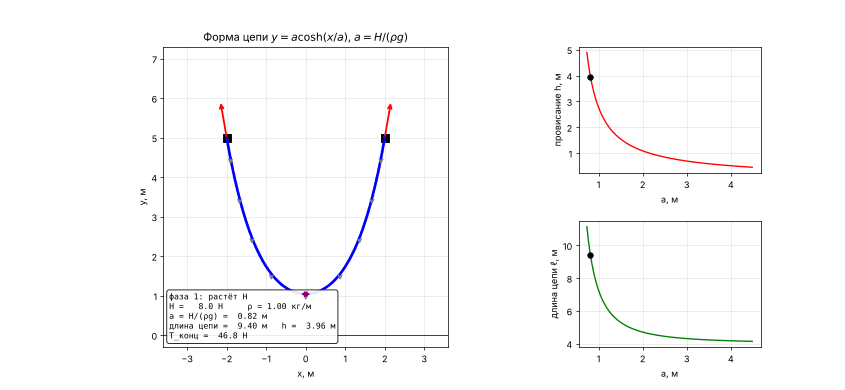

In [7]:
L, y_e = 2.0, 5.0                                            # полупролёт и высота опор
n1, n2 = 40, 40                                              # кадры первой и второй фаз
H_arr = np.concatenate([np.linspace(8, 40, n1), np.full(n2, 40.0)])       # горизонтальное натяжение, Н
rho_arr = np.concatenate([np.full(n1, 1.0), np.linspace(1, 4, n2)])       # линейная плотность, кг/м
a_arr = H_arr/(rho_arr*g)                                    # параметр a = H/(ρ g)
n_frames = n1 + n2
aa = np.linspace(a_arr.min()*0.9, a_arr.max()*1.1, 200)

fig = plt.figure(figsize=(13, 6), dpi=65)
gs = fig.add_gridspec(2, 2, width_ratios=[2.2, 1], hspace=0.38, wspace=0.25)
ax = fig.add_subplot(gs[:, 0]); axh = fig.add_subplot(gs[0, 1]); axl = fig.add_subplot(gs[1, 1])

ax.plot([-L, L], [y_e, y_e], 'ks', ms=9)                      # опоры
chain, = ax.plot([], [], 'b-', lw=3)
ax.axhline(0, color='k', lw=0.8)
ax.set_xlim(-3.6, 3.6); ax.set_ylim(-0.3, 7.3); ax.set_aspect('equal')
ax.set_xlabel('x, м'); ax.set_ylabel('y, м'); ax.grid(alpha=0.3)
ax.set_title('Форма цепи $y=a\\cosh(x/a)$, $a=H/(\\rho g)$')
info = ax.text(0.02, 0.02, '', transform=ax.transAxes, va='bottom', family='monospace', fontsize=9, bbox=dict(boxstyle='round', fc='white', alpha=0.9))
arrow_artists = []                                           # динамические стрелки (будем удалять и рисовать заново)
k_force = 0.02                                               # масштаб стрелок: метров на ньютон

axh.plot(aa, [sag(a_, L) for a_ in aa], 'r-'); axh.set_xlabel('a, м'); axh.set_ylabel('провисание h, м'); axh.grid(alpha=0.3)
axl.plot(aa, 2*aa*np.sinh(L/aa), 'g-'); axl.set_xlabel('a, м'); axl.set_ylabel('длина цепи ℓ, м'); axl.grid(alpha=0.3)
mk_h, = axh.plot([], [], 'ko'); mk_l, = axl.plot([], [], 'ko')

def update(k):
    a_, H, rho = a_arr[k], H_arr[k], rho_arr[k]
    xx = np.linspace(-L, L, 200); chain.set_data(xx, catenary(xx, a_, y_vertex=y_e - sag(a_, L)))
    for art in arrow_artists: art.remove()                    # стираем стрелки предыдущего кадра
    arrow_artists.clear()
    y_v = y_e - sag(a_, L)                                    # высота вершины
    ell = 2*a_*np.sinh(L/a_); T_end = rho*g*a_*np.cosh(L/a_); phi = np.arctan(np.sinh(L/a_))
    # веса 9 элементов: середины дуг, s = a·sh(x/a)  =>  x = a·arsh(s/a)
    s_mid = (np.arange(9) + 0.5)/9*ell - ell/2
    xm = a_*np.arcsinh(s_mid/a_); ym = catenary(xm, a_, y_vertex=y_v)
    w_el = rho*g*ell/9                                        # вес одного элемента, Н
    for xi, yi in zip(xm, ym):
        arrow_artists.append(ax.annotate('', xy=(xi, yi - k_force*w_el), xytext=(xi, yi), arrowprops=dict(arrowstyle='->', color='gray', lw=1.5), annotation_clip=False))
    # натяжения на концах (сила, с которой опора действует на цепь: по касательной наружу-вверх)
    for sgn in (-1, 1):
        arrow_artists.append(ax.annotate('', xy=(sgn*L + sgn*k_force*T_end*np.cos(phi), y_e + k_force*T_end*np.sin(phi)), xytext=(sgn*L, y_e),
                                         arrowprops=dict(arrowstyle='->', color='red', lw=2), annotation_clip=False))
    # горизонтальное натяжение H у вершины: две стрелки в стороны
    for sgn in (-1, 1):
        arrow_artists.append(ax.annotate('', xy=(sgn*k_force*H, y_v), xytext=(0, y_v), arrowprops=dict(arrowstyle='->', color='purple', lw=2), annotation_clip=False))
    phase = 'фаза 1: растёт H' if k < n1 else 'фаза 2: растёт ρ'
    info.set_text(f'{phase}\nH = {H:5.1f} Н     ρ = {rho:4.2f} кг/м\na = H/(ρg) = {a_:5.2f} м\nдлина цепи = {ell:5.2f} м   h = {sag(a_, L):5.2f} м\nT_конц = {T_end:5.1f} Н')
    mk_h.set_data([a_], [sag(a_, L)]); mk_l.set_data([a_], [ell])
    return chain,

anim = FuncAnimation(fig, update, frames=n_frames, interval=70, blit=False)
anim.save('task_3_3_anim.gif', writer=PillowWriter(fps=16), dpi=65)
display(Image(filename='task_3_3_anim.gif'))
plt.rcParams['animation.frame_format'] = 'jpeg'                       # кадры HTML-плеера в JPEG: файл ноутбука заметно меньше
display(HTML(anim.to_jshtml(fps=16)))
plt.close(fig)

## 5. Выводы и ответ

Форма равновесия однородной тяжёлой нерастяжимой нити — **цепная линия**
$$
y=a\cosh\frac xa,\qquad a=\frac{H}{\rho g},
$$
где $H$ — горизонтальное натяжение (одинаковое во всех точках), $\rho$ — линейная плотность. Параметр $a$ — единственный масштаб формы: большие $a$ (сильное натяжение, лёгкая цепь) — почти плоская цепь, малые $a$ — сильное провисание. Дополнительно: $s=a\sinh(x/a)$, $T=\rho g y$, $R=y^2/a$; для цепи на опорах $\ell=2a\sinh(L/a)$, $h=a(\cosh(L/a)-1)$. Все формулы проверены символьно, численным решением ОДУ и независимой минимизацией энергии дискретной цепочки.

Файлы, создаваемые ноутбуком: `task_3_3_static.png` и `task_3_3_anim.gif`.